### CC0F4 - Examen Parcial
#### Del prototipo LLM y la recuperación densa a un sistema RAG evaluable

**Estudiante:** César Augusto Sánchez Malaspina · **Periodo:** 2026-2
**Tema (PC1):** Agente de revisión científica que identifica desacuerdos entre artículos mediante citation context y generación estructurada

Este cuaderno es la **versión ejecutable completa** del examen. Continúa PC1 (`../../src/`) y construye, en orden:

```text
problema del proyecto
-> consulta estructurada y validada           (sección 2)
-> recuperación densa / híbrida / reranking   (secciones 4-6)
-> evidencia top-k                            (sección 7)
-> respuesta RAG con citas                    (sección 8)
-> evaluación y análisis de errores           (secciones 7-9)

herramienta local independiente
-> contrato -> validación -> ejecución o error estructurado   (sección 10)
```

**Pregunta experimental.** Con corpus, consultas, qrels, segmentación, modelos y decoding fijos: ¿qué aporta cada etapa de recuperación a la evidencia recuperada, y cuánto cambian la corrección y la fidelidad de la respuesta del mismo LLM cuando recibe esa evidencia?

| Sección | Contenido | Semana |
|---|---|---|
| 1 | Configuración fijada antes de ejecutar | 4, 5, 7 |
| 2 | Contratos: consulta estructurada y respuesta RAG | 3 |
| 3 | Corpus real de arXiv, consultas y qrels | 4, 7 |
| 4 | Segmentación (chunking con overlap) | 4 |
| 5 | Métricas desde cero | 7 |
| 6 | Recuperadores: E5 + FAISS, BM25, RRF, Cross-Encoder | 4, 5 |
| 7 | **Experimento 1** - Recuperación A / B / C | 5, 7 |
| 8 | **Experimento 2** - Closed-book vs RAG | 2, 3, 5, 7 |
| 9 | Inspección del modelo: arquitectura, máscara causal, logits, KV cache | 1, 2 |
| 10 | **Experimento 3** - Herramienta con contratos | 6 |
| 11 | Demostración de la defensa | todas |
| 12 | Conclusiones | — |

Ejecutar con el kernel `Python (cc0f4-parcial)` desde `parcial/notebooks/`: *Run All* (unos 5 minutos en CPU). Los modelos se descargan del Hub la primera vez.

#### **1. Configuración**

Todos los parámetros se fijan **antes** de ejecutar y no se cambian después de ver las métricas.

En macOS, `faiss-cpu` y `torch` cargan runtimes OpenMP distintos y el proceso terminaba con *segfault* (código 139). Se fija un solo hilo **antes** de importar ambos, lo que además deja las latencias de las etapas medidas con el mismo perfil de CPU.

In [1]:
import os
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")

import asyncio
import hashlib
import json
import math
import platform
import re
import time
from collections import Counter, defaultdict
from dataclasses import dataclass
from datetime import date, datetime, timezone
from enum import Enum
from importlib import metadata
from pathlib import Path
from typing import Any, Literal

import numpy as np
import pandas as pd

pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 90)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "data"
PROMPTS_DIR = ROOT / "prompts"
RESULTS_DIR = ROOT / "results"
RAW_PATH = DATA_DIR / "raw" / "arxiv_raw.json"
CORPUS_PATH = DATA_DIR / "corpus.jsonl"
QUERIES_PATH = DATA_DIR / "queries.jsonl"
QRELS_PATH = DATA_DIR / "qrels.json"
REFERENCE_PATH = DATA_DIR / "reference_answers.jsonl"
assert CORPUS_PATH.exists(), f"Ejecuta el cuaderno desde parcial/notebooks (ROOT={ROOT})"

SEED = 42
np.random.seed(SEED)

# Modelos
DENSE_MODEL_ID = "intfloat/multilingual-e5-small"
RERANKER_MODEL_ID = "cross-encoder/mmarco-mMiniLMv2-L12-H384-v1"
GENERATOR_MODEL_ID = "Qwen/Qwen2.5-0.5B-Instruct"
DEVICE = "cpu"

# Segmentación (con 180 palabras casi todo abstract queda en un solo chunk)
MIN_PASSAGE_WORDS = 35
TARGET_WORDS = 100
OVERLAP_PASSAGES = 1

# Recuperación
CANDIDATE_DEPTH = 10
TOP_K_VALUES = [1, 3, 5]
NDCG_K = 5
RRF_CONSTANT = 60
BM25_K1, BM25_B, BM25_EPSILON = 1.5, 0.75, 0.25
BM25_TOKENIZER_VERSION = "regex-unicode-lower-en-stopwords-v1"

# Stopwords en inglés; se conservan palabras que cambian el sentido de la consulta
BM25_PRESERVED_TERMS = frozenset({"no", "not", "without", "more", "less", "than", "always", "only"})
ENGLISH_STOPWORDS = frozenset({
    "a", "an", "and", "are", "as", "at", "be", "by", "can", "do", "does", "for",
    "from", "has", "have", "how", "in", "is", "it", "its", "of", "on", "or",
    "such", "that", "the", "their", "them", "these", "this", "to", "was", "we",
    "what", "when", "which", "while", "with", "should", "instead", "much",
}) - BM25_PRESERVED_TERMS

# Bootstrap
BOOTSTRAP_RESAMPLES = 5000
BOOTSTRAP_ALPHA = 0.05

# RAG
RAG_CONDITION = "C_hybrid_rrf_reranker"
RAG_TOP_K = 3                             # chunks que recibe el LLM
MAX_NEW_TOKENS = 220
DO_SAMPLE = False                         # greedy
# Qwen trae repetition_penalty=1.1 por defecto; con 1.0 es greedy puro (ver sección 9)
REPETITION_PENALTY = 1.0
RAG_QUERY_IDS = ["Q01", "Q02", "Q07", "Q09", "Q10", "Q12", "Q13", "Q17", "Q18", "Q19", "Q21", "Q22"]

print("ROOT:", ROOT)
print("Python", platform.python_version(), "·", {p: metadata.version(p) for p in
      ["torch", "transformers", "sentence-transformers", "faiss-cpu", "rank-bm25", "pydantic"]})

ROOT: /Users/cesar/Desktop/Parcial-TOPICOS1-SanchezMalaspinaCesar/parcial
Python 3.12.3 · {'torch': '2.14.1', 'transformers': '5.21.0', 'sentence-transformers': '6.2.0', 'faiss-cpu': '1.15.1', 'rank-bm25': '0.2.2', 'pydantic': '2.14.1'}


#### **2. Contratos (Semana 3)**

Se extiende el contrato de PC1 (`../../src/schema.py`: `CitationRelationOutput` con `RelationEnum`) en dos puntos:

```text
necesidad de información -> StructuredQuery (validada antes de recuperar)
evidencia + pregunta     -> RAGAnswer {relation, answer, citations, confidence}
```

- **Validación estructural** (Pydantic / JSON Schema): tipos, enum, longitudes, rango de `confidence`.
- **Validación de dominio**: el `topic` debe pertenecer al corpus declarado.
- **Validación semántica** (lo que el schema no puede expresar): las citas deben estar en el contexto entregado, y afirmar una relación sin citar evidencia es un problema.

`RAGRelation` agrega `insufficient_evidence` al `RelationEnum` de PC1 para permitir la **abstención**.

In [2]:
from pydantic import BaseModel, Field, ValidationError, field_validator, model_validator

TOPICS = {
    "scaling_laws", "emergence", "chain_of_thought", "rag_vs_finetuning",
    "attention_heads", "alignment", "quantization", "positional_encoding",
    "efficient_attention", "dense_vs_sparse_retrieval", "in_context_learning", "peft",
}


class Difficulty(str, Enum):
    CLEAR = "clear"
    AMBIGUOUS = "ambiguous"
    HARD = "hard"
    DISTRACTOR = "distractor"
    NO_ANSWER = "no_answer"


class StructuredQuery(BaseModel):
    query_id: str = Field(pattern=r"^Q\d{2}$")
    query: str = Field(min_length=15)
    query_es: str = Field(min_length=10)
    topic: str
    claim_under_test: str = Field(min_length=10)
    difficulty: Difficulty

    @field_validator("topic")
    @classmethod
    def topic_in_domain(cls, value: str) -> str:
        if value not in TOPICS:
            raise ValueError(f"topic fuera del dominio: {value}")
        return value


class RAGRelation(str, Enum):
    AGREE = "agree"
    DISAGREE = "disagree"
    NEUTRAL = "neutral"
    INSUFFICIENT = "insufficient_evidence"


class RAGAnswer(BaseModel):
    relation: RAGRelation
    answer: str = Field(min_length=5)
    citations: list[str] = Field(default_factory=list)
    confidence: float = Field(ge=0.0, le=1.0)


def semantic_check(answer: RAGAnswer, context_passage_ids: set[str]) -> list[str]:
    problems = []
    outside = [c for c in answer.citations if c not in context_passage_ids]
    if outside:
        problems.append(f"citas fuera del contexto: {outside}")
    if answer.relation != RAGRelation.INSUFFICIENT and context_passage_ids and not answer.citations:
        problems.append("afirma una relación sin citar evidencia")
    return problems


# Pruebas
try:
    StructuredQuery(query_id="Q99", query="Does X beat Y on Z?", query_es="¿X supera a Y?",
                    topic="astrology", claim_under_test="X beats Y.", difficulty="clear")
    raise AssertionError("debió fallar")
except ValidationError as exc:
    assert "topic fuera del dominio" in str(exc)
try:
    RAGAnswer(relation="agree", answer="Yes", citations=[], confidence=1.0)
    raise AssertionError("debió fallar")
except ValidationError:
    pass
ok = RAGAnswer(relation="agree", answer="Both papers report X.", citations=["P9"], confidence=0.8)
assert semantic_check(ok, {"P1"}) == ["citas fuera del contexto: ['P9']"]
print("Contratos: OK")
print(json.dumps(RAGAnswer.model_json_schema(), indent=1)[:600], "...")

Contratos: OK
{
 "$defs": {
  "RAGRelation": {
   "enum": [
    "agree",
    "disagree",
    "neutral",
    "insufficient_evidence"
   ],
   "title": "RAGRelation",
   "type": "string"
  }
 },
 "properties": {
  "relation": {
   "$ref": "#/$defs/RAGRelation"
  },
  "answer": {
   "minLength": 5,
   "title": "Answer",
   "type": "string"
  },
  "citations": {
   "items": {
    "type": "string"
   },
   "title": "Citations",
   "type": "array"
  },
  "confidence": {
   "maximum": 1.0,
   "minimum": 0.0,
   "title": "Confidence",
   "type": "number"
  }
 },
 "required": [
  "relation",
  "answer",
  "confidenc ...


#### **3. Corpus real, consultas y qrels**

**Procedencia.** API pública de arXiv (`export.arxiv.org/api/query`). Solo metadatos y abstracts, que arXiv distribuye bajo **CC0 1.0**. Se eligieron 36 artículos sobre 12 debates de ML/NLP **antes** de escribir las consultas.

**Formato** heredado de `Semana4/datos/corpus_semana4.jsonl`:

```text
{"doc_id", "title", "passages": [{"passage_id", "text"}], ...metadatos de procedencia}
```

**Identificadores estables:** `doc_id` = arXiv ID (`2203.15556`) y `passage_id` = `2203.15556-P02`. La versión exacta queda en `arxiv_version`.

**Segmentación en passages:** las oraciones del abstract se agrupan hasta alcanzar 35 palabras o más, sin cortar «e.g.», «i.e.» ni «et al.». El passage es la **unidad atómica de relevancia**.

In [3]:
raw = json.loads(RAW_PATH.read_text())
assert len(raw["papers"]) == 36 and len({p["arxiv_id"] for p in raw["papers"]}) == 36
print("Descargado:", raw["retrieved_at"], "·", len(raw["papers"]), "artículos ·", raw["license"])

Descargado: 2026-10-27T12:19:31+00:00 · 36 artículos · Metadatos y abstracts de arXiv: CC0 1.0 (https://info.arxiv.org/help/api/tou.html)


In [4]:
# Corta oraciones sin partir "e.g.", "i.e." ni "et al."
SENTENCE_RE = re.compile(r"(?<!\be\.g\.)(?<!\bi\.e\.)(?<!\bal\.)(?<=[.!?])\s+(?=[A-Z0-9(])")


def split_sentences(text: str) -> list[str]:
    return [s.strip() for s in SENTENCE_RE.split(text) if s.strip()]


def group_passages(sentences: list[str], min_words: int = MIN_PASSAGE_WORDS) -> list[str]:
    passages, current = [], []
    for sentence in sentences:
        current.append(sentence)
        if len(" ".join(current).split()) >= min_words:
            passages.append(" ".join(current))
            current = []
    if current:
        # Si sobra un pedazo corto, se une al passage anterior
        if passages and len(" ".join(current).split()) < min_words // 2:
            passages[-1] = passages[-1] + " " + " ".join(current)
        else:
            passages.append(" ".join(current))
    return passages


assert split_sentences("We use e.g. BM25. Results improve.") == ["We use e.g. BM25.", "Results improve."]

with CORPUS_PATH.open("w") as f:
    for paper in sorted(raw["papers"], key=lambda p: (p["topic"], p["published"])):
        texts = group_passages(split_sentences(paper["abstract"]))
        f.write(json.dumps({
            "doc_id": paper["arxiv_id"], "title": paper["title"], "topic": paper["topic"],
            "year": int(paper["published"][:4]),
            "authors": paper["authors"][:3] + (["et al."] if len(paper["authors"]) > 3 else []),
            "source_url": paper["url"], "arxiv_version": paper["arxiv_version"],
            "corpus_version": "parcial-v1",
            "passages": [{"passage_id": f"{paper['arxiv_id']}-P{i:02d}", "text": t}
                         for i, t in enumerate(texts, start=1)],
        }, ensure_ascii=False) + "\n")
print("Corpus reconstruido desde raw: OK")

Corpus reconstruido desde raw: OK


**Consultas y qrels.** Se escribieron 20 consultas con dificultad declarada y se anotaron sus qrels **leyendo los 135 passages, antes de ejecutar cualquier sistema**:

- grado **2**: el passage responde directamente;
- grado **1**: aporta contexto o solo una de las dos posturas.

Las 2 consultas `no_answer` (Mamba, Llama 3) no tienen evidencia en el corpus: se excluyen de Recall/MRR/nDCG y se usan en el experimento 2 para evaluar la abstención. La validación falla temprano si el benchmark es inconsistente.

In [5]:
def read_jsonl(path: Path) -> list[dict[str, Any]]:
    return [json.loads(line) for line in path.read_text().splitlines() if line.strip()]


def sha256_file(path: Path) -> str:
    return hashlib.sha256(path.read_bytes()).hexdigest()


def validate_benchmark(documents, queries, qrels) -> None:
    passage_ids = [p["passage_id"] for d in documents for p in d["passages"]]
    if len(passage_ids) != len(set(passage_ids)):
        raise ValueError("passage_id duplicado en el corpus")
    texts = [p["text"] for d in documents for p in d["passages"]]
    if len(texts) != len(set(texts)):
        raise ValueError("texto de passage duplicado: el corpus no debe inflarse")
    known = set(passage_ids)
    if set(qrels) != {q.query_id for q in queries}:
        raise ValueError("qrels y queries no cubren las mismas query_id")
    for q in queries:
        judged = qrels[q.query_id]
        if q.difficulty == Difficulty.NO_ANSWER:
            if judged:
                raise ValueError(f"{q.query_id} es no_answer pero tiene qrels")
            continue
        if not judged:
            raise ValueError(f"{q.query_id} no tiene passages relevantes")
        if set(judged) - known:
            raise ValueError(f"{q.query_id} referencia passages inexistentes")
        if any(g not in (1, 2) for g in judged.values()):
            raise ValueError(f"{q.query_id}: grados de relevancia deben ser 1 o 2")


documents = read_jsonl(CORPUS_PATH)
queries = [StructuredQuery.model_validate(q) for q in read_jsonl(QUERIES_PATH)]
qrels = json.loads(QRELS_PATH.read_text())
references = {r["query_id"]: r for r in read_jsonl(REFERENCE_PATH)}
validate_benchmark(documents, queries, qrels)

query_by_id = {q.query_id: q for q in queries}
retrieval_qs = [q for q in queries if q.difficulty != Difficulty.NO_ANSWER]
passages_by_id = {p["passage_id"]: {**p, "title": d["title"], "year": d["year"]}
                  for d in documents for p in d["passages"]}
n_rel = [len(v) for v in qrels.values() if v]

print("Benchmark válido: OK")
pd.DataFrame({
    "documentos": [len(documents)], "passages": [len(passages_by_id)],
    "consultas_recuperación": [len(retrieval_qs)], "consultas_no_answer": [len(queries) - len(retrieval_qs)],
    "juicios": [sum(n_rel)], "relevantes_por_consulta": [round(np.mean(n_rel), 2)],
    "años": [f"{min(d['year'] for d in documents)}-{max(d['year'] for d in documents)}"],
})

Benchmark válido: OK


,documentos,passages,consultas_recuperación,consultas_no_answer,juicios,relevantes_por_consulta,años
0,36,135,20,2,56,2.8,2017-2024


In [6]:
display(pd.Series(Counter(q.difficulty.value for q in queries), name="consultas por dificultad").to_frame().T)
pd.DataFrame([{"query_id": q.query_id, "dificultad": q.difficulty.value, "topic": q.topic,
               "consulta": q.query, "qrels": qrels[q.query_id]} for q in queries]).set_index("query_id")

,hard,clear,distractor,ambiguous,no_answer
consultas por dificultad,5,10,2,3,2


,dificultad,topic,consulta,qrels
query_id,,,,
Q01,hard,scaling_laws,Do Kaplan-style scaling laws and the Chinchilla study agree on how to split a fixed co...,"{'2001.08361-P03': 2, '2203.15556-P02': 2, '2203.15556-P01': 1}"
Q02,clear,emergence,Are emergent abilities of large language models a real effect of scale or an artifact ...,"{'2304.15004-P02': 2, '2304.15004-P03': 2, '2304.15004-P04': 2, '2206.07682-P02': 1}"
Q03,distractor,emergence,Which work defines an ability as emergent when it is absent in smaller models and cann...,"{'2206.07682-P02': 2, '2206.07682-P01': 1}"
Q04,clear,chain_of_thought,Are chain-of-thought explanations a faithful account of why the model produced its ans...,"{'2305.04388-P02': 2, '2305.04388-P04': 2, '2305.04388-P03': 1, '2305.04388-P05': 1}"
Q05,ambiguous,chain_of_thought,Do language models need hand-crafted few-shot exemplars to benefit from step-by-step r...,"{'2205.11916-P02': 2, '2201.11903-P01': 1}"
Q06,clear,chain_of_thought,Does sampling several reasoning paths and taking the most consistent answer beat greed...,"{'2203.11171-P01': 2, '2203.11171-P02': 2, '2203.11171-P03': 2}"
Q07,clear,rag_vs_finetuning,"For injecting new factual knowledge into an LLM, is retrieval-augmented generation bet...","{'2312.05934-P03': 2, '2312.05934-P04': 1, '2005.11401-P05': 1}"
Q08,ambiguous,rag_vs_finetuning,Do language models use relevant information placed in the middle of a long input conte...,{'2307.03172-P02': 2}
Q09,hard,attention_heads,Does sharing keys and values across attention heads degrade model quality compared wit...,"{'1911.02150-P03': 2, '2305.13245-P01': 2, '2305.13245-P02': 2, '1911.02150-P02': 1}"


#### **4. Segmentación (Semana 4)**

`build_chunks` agrupa passages consecutivos hasta `target_words` **sin romperlos**, con un overlap de `overlap_passages`.

```text
passages:  P1  P2  P3  P4
chunks:   [P1  P2]
              [P2  P3]
                  [P3  P4]
```

La relevancia se define sobre **passages**, no sobre chunks: si cambia la segmentación, los qrels siguen siendo válidos.

In [7]:
def word_count(text: str) -> int:
    return len(text.split())


def build_chunks(documents: list[dict], target_words: int, overlap_passages: int) -> list[dict]:
    if target_words <= 0:
        raise ValueError("target_words debe ser > 0")
    if overlap_passages < 0:
        raise ValueError("overlap_passages debe ser >= 0")
    chunks = []
    for doc in documents:
        passages = doc["passages"]
        start, chunk_number = 0, 1
        while start < len(passages):
            selected, total_words, end = [], 0, start
            while end < len(passages):
                n_words = word_count(passages[end]["text"])
                if selected and total_words + n_words > target_words:
                    break
                selected.append(passages[end])
                total_words += n_words
                end += 1
            chunks.append({
                "chunk_id": f"{doc['doc_id']}-C{chunk_number:03d}", "doc_id": doc["doc_id"],
                "title": doc["title"], "year": doc["year"],
                "passage_ids": [p["passage_id"] for p in selected], "n_words": total_words,
                "text": " ".join(p["text"] for p in selected),
            })
            if end >= len(passages):
                break
            start = max(start + 1, end - overlap_passages)
            chunk_number += 1
    return chunks


demo_doc = {"doc_id": "D", "title": "t", "year": 2020,
            "passages": [{"passage_id": f"D-P{i}", "text": "w " * 40} for i in range(1, 5)]}
assert [c["passage_ids"] for c in build_chunks([demo_doc], 100, 1)] == \
    [["D-P1", "D-P2"], ["D-P2", "D-P3"], ["D-P3", "D-P4"]]
print("Overlap de chunks: OK")

chunks = build_chunks(documents, TARGET_WORDS, OVERLAP_PASSAGES)
whole = sum(1 for d in documents if len(build_chunks([d], 180, OVERLAP_PASSAGES)) == 1)
print(f"Chunks: {len(chunks)} · palabras promedio {np.mean([c['n_words'] for c in chunks]):.1f}"
      f" · máximo {max(c['n_words'] for c in chunks)}")
print(f"Con target_words=180 (línea base S4), {whole} de {len(documents)} documentos quedarían en un único chunk.")

Overlap de chunks: OK
Chunks: 110 · palabras promedio 74.0 · máximo 116
Con target_words=180 (línea base S4), 20 de 36 documentos quedarían en un único chunk.


#### **5. Métricas desde cero (Semana 7)**

Los chunks se expanden a un ranking de **passages**, sin repetir los passages del overlap (`expand_to_passage_ranking`).

$$Recall@k(q)=\frac{|R_q \cap L_q^{(k)}|}{|R_q|} \qquad RR(q)=\frac{1}{\text{rank del primer relevante}} \qquad nDCG@k=\frac{DCG@k}{IDCG@k},\; DCG@k=\sum_{i=1}^{k}\frac{2^{rel_i}-1}{\log_2(i+1)}$$

Los qrels son **graduados**. Recall y RR usan relevancia binaria (grado ≥ 1); nDCG usa la ganancia graduada.

**Bootstrap pareado:** se remuestrean las consultas con reemplazo 5000 veces. Si el IC95 de la diferencia cruza 0, no se puede afirmar que un sistema supere al otro en este benchmark.

In [8]:
def expand_to_passage_ranking(ranked_chunks: list[dict]) -> list[str]:
    ordered, seen = [], set()
    for chunk in ranked_chunks:
        for pid in chunk["passage_ids"]:
            if pid not in seen:
                ordered.append(pid)
                seen.add(pid)
    return ordered


def recall_at_k(ranking: list[str], qrels_q: dict[str, int], k: int) -> float:
    relevant = {p for p, g in qrels_q.items() if g >= 1}
    return len(relevant & set(ranking[:k])) / len(relevant)


def reciprocal_rank(ranking: list[str], qrels_q: dict[str, int]) -> float:
    for rank, pid in enumerate(ranking, start=1):
        if qrels_q.get(pid, 0) >= 1:
            return 1.0 / rank
    return 0.0


def dcg_at_k(grades: list[int], k: int) -> float:
    return sum((2.0 ** g - 1.0) / math.log2(i + 1) for i, g in enumerate(grades[:k], start=1))


def ndcg_at_k(ranking: list[str], qrels_q: dict[str, int], k: int) -> float:
    idcg = dcg_at_k(sorted(qrels_q.values(), reverse=True), k)
    return dcg_at_k([qrels_q.get(p, 0) for p in ranking], k) / idcg if idcg > 0 else 0.0


def paired_bootstrap_delta(frame, metric, cond_a, cond_b, n_resamples=BOOTSTRAP_RESAMPLES,
                           alpha=BOOTSTRAP_ALPHA, seed=SEED) -> dict[str, Any]:
    a = frame.loc[frame["condition"] == cond_a].set_index("query_id")[metric].sort_index()
    b = frame.loc[frame["condition"] == cond_b].set_index("query_id")[metric].sort_index()
    if list(a.index) != list(b.index):
        raise ValueError("La comparación pareada requiere las mismas query_id.")
    deltas = b.to_numpy(dtype=float) - a.to_numpy(dtype=float)
    rng = np.random.default_rng(seed)
    means = np.array([deltas[rng.integers(0, len(deltas), len(deltas))].mean() for _ in range(n_resamples)])
    low, high = float(np.quantile(means, alpha / 2)), float(np.quantile(means, 1 - alpha / 2))
    return {"metric": metric, "comparison": f"{cond_b} - {cond_a}", "n_queries": len(deltas),
            "delta_mean": float(deltas.mean()), "ci95_low": low, "ci95_high": high,
            "ci_crosses_zero": bool(low <= 0.0 <= high), "wins": int((deltas > 0).sum()),
            "ties": int((deltas == 0).sum()), "losses": int((deltas < 0).sum())}


def classify_retrieval_failure(ranked_chunks, qrels_q, top_k: int = 3) -> str:
    ranking = expand_to_passage_ranking(ranked_chunks)
    if recall_at_k(ranking, qrels_q, max(CANDIDATE_DEPTH, len(ranking))) == 0:
        return "RETRIEVAL_MISS"
    top = recall_at_k(ranking, qrels_q, top_k)
    if top == 0:
        return "RANKING_ERROR"
    return "PARTIAL_RECALL" if top < 1 else "RETRIEVAL_OK"


def citation_metrics(citations: list[str], context_ids: set[str], qrels_q: dict[str, int]) -> dict:
    if not citations:
        return {"n_citations": 0, "citation_in_context_rate": float("nan"), "citation_support_rate": float("nan")}
    return {"n_citations": len(citations),
            "citation_in_context_rate": sum(c in context_ids for c in citations) / len(citations),
            "citation_support_rate": sum(qrels_q.get(c, 0) >= 1 for c in citations) / len(citations)}


# Mismo recall, distinto orden
r_a, r_b, rel = ["R", "X", "Y", "Z"], ["X", "Y", "R", "Z"], {"R": 1}
assert recall_at_k(r_a, rel, 4) == recall_at_k(r_b, rel, 4) == 1.0
assert reciprocal_rank(r_a, rel) > reciprocal_rank(r_b, rel)
assert ndcg_at_k(r_a, rel, 4) > ndcg_at_k(r_b, rel, 4)
# Con grados: la evidencia directa primero vale más
assert math.isclose(ndcg_at_k(["D", "P"], {"D": 2, "P": 1}, 5), 1.0) and ndcg_at_k(["P", "D"], {"D": 2, "P": 1}, 5) < 1
assert expand_to_passage_ranking([{"passage_ids": ["P1", "P2"]}, {"passage_ids": ["P2", "P3"]}]) == ["P1", "P2", "P3"]
print("Tests de métricas: OK")
print(f"Cota superior de Recall@1 en este benchmark: {np.mean([1 / n for n in n_rel]):.4f} "
      f"(hay {np.mean(n_rel):.1f} relevantes por consulta en promedio)")

Tests de métricas: OK
Cota superior de Recall@1 en este benchmark: 0.4375 (hay 2.8 relevantes por consulta en promedio)


#### **6. Recuperadores (Semanas 4 y 5)**

```text
                    +-> E5 "query:" + FAISS IndexFlatIP ------+
consulta -----------+                                          +-> RRF (k=60) -> Cross-Encoder -> top-k
                    +-> BM25Okapi (k1=1.5, b=0.75) ------------+
```

| Componente | Cómo funciona | Por qué |
|---|---|---|
| **E5 + FAISS** (A) | *Bi-encoder*: consulta y passage se codifican **por separado** con prefijos `query:` / `passage:`, se normalizan con L2 y `IndexFlatIP` calcula el producto interno (= coseno) | Búsqueda exacta; con 110 vectores no hace falta un índice aproximado |
| **BM25** | Coincidencia léxica con saturación de frecuencia (`k1`) y normalización por longitud (`b`) | Rescata términos exactos que el embedding diluye |
| **RRF** (B) | $RRF(d)=\sum_r \frac{1}{k+r(d)}$: fusiona **posiciones**, no scores | Los scores de BM25 (~10) y del coseno (~0,8) no son comparables |
| **Cross-Encoder** (C) | Lee `(consulta, passage)` **juntos** y produce un score de relevancia | Más preciso, pero no se puede pre-indexar: solo reordena los 10 candidatos de RRF |

Los empates se resuelven por `chunk_id` para mantener el determinismo. La latencia se mide **solo en tiempo de consulta**: excluye la carga de modelos y la construcción del índice, e incluye el embedding de la consulta. Las etapas se ejecutan en secuencia.

In [9]:
import faiss
from rank_bm25 import BM25Okapi
from sentence_transformers import CrossEncoder, SentenceTransformer


def lexical_tokenize(text: str) -> list[str]:
    tokens = re.findall(r"\b\w+\b", text.lower(), flags=re.UNICODE)
    return [t for t in tokens if t not in ENGLISH_STOPWORDS]


def stable_order(scores: np.ndarray, items: list[dict], depth: int) -> list[int]:
    return sorted(range(len(scores)), key=lambda i: (-float(scores[i]), items[i]["chunk_id"]))[:depth]


def reciprocal_rank_fusion(rankings, depth: int = CANDIDATE_DEPTH, rank_constant: int = RRF_CONSTANT):
    scores, payload, sources = defaultdict(float), {}, defaultdict(list)
    for ranking in rankings:
        for item in ranking:
            cid = item["chunk_id"]
            scores[cid] += 1.0 / (rank_constant + item["rank"])
            payload[cid] = {k: v for k, v in item.items() if k not in {"score", "rank", "source"}}
            sources[cid].append(item["source"])
    ordered = sorted(scores, key=lambda cid: (-scores[cid], cid))[:depth]
    return [{**payload[cid], "score": float(scores[cid]), "rank": r,
             "source": "+".join(sorted(set(sources[cid])))} for r, cid in enumerate(ordered, start=1)]


class Retrievers:
    def __init__(self, chunks: list[dict]):
        self.chunks = chunks
        texts = [c["text"] for c in chunks]
        self.bm25 = BM25Okapi([lexical_tokenize(t) for t in texts], k1=BM25_K1, b=BM25_B, epsilon=BM25_EPSILON)

        self.encoder = SentenceTransformer(DENSE_MODEL_ID, device=DEVICE)
        doc_inputs = [f"passage: {t}" for t in texts]  # E5 usa prefijos
        self.max_doc_tokens = max(len(self.encoder.tokenizer(t)["input_ids"]) for t in doc_inputs)
        if self.max_doc_tokens > self.encoder.max_seq_length:
            raise ValueError(f"Un chunk excede el límite del encoder: {self.max_doc_tokens}")
        vectors = self.encoder.encode(doc_inputs, normalize_embeddings=True, convert_to_numpy=True,
                                      show_progress_bar=False).astype("float32")
        self.index = faiss.IndexFlatIP(vectors.shape[1])  # producto interno = coseno
        self.index.add(vectors)
        self.dim = vectors.shape[1]

        self.reranker = CrossEncoder(RERANKER_MODEL_ID, max_length=512, device=DEVICE)

    def _items(self, order, scores, source):
        return [{**self.chunks[i], "score": float(scores[i]), "rank": r, "source": source}
                for r, i in enumerate(order, start=1)]

    def bm25_ranking(self, query: str, depth: int = CANDIDATE_DEPTH):
        scores = np.asarray(self.bm25.get_scores(lexical_tokenize(query)), dtype=float)
        return self._items(stable_order(scores, self.chunks, depth), scores, "bm25")

    def dense_ranking(self, query: str, depth: int = CANDIDATE_DEPTH):
        qvec = self.encoder.encode([f"query: {query}"], normalize_embeddings=True,
                                   convert_to_numpy=True, show_progress_bar=False).astype("float32")
        # Se ordena todo y se corta a depth
        scores, idx = self.index.search(qvec, int(self.index.ntotal))
        full = np.full(len(self.chunks), -np.inf)
        full[idx[0]] = scores[0]
        return self._items(stable_order(full, self.chunks, depth), full, "dense")

    def rerank(self, query: str, candidates: list[dict]):
        if not candidates:
            return []
        scores = np.asarray(self.reranker.predict([(query, c["text"]) for c in candidates],
                                                  batch_size=8, show_progress_bar=False), dtype=float).reshape(-1)
        order = sorted(range(len(candidates)), key=lambda i: (-scores[i], candidates[i]["chunk_id"]))
        return [{**candidates[i], "pre_rerank_rank": candidates[i]["rank"], "score": float(scores[i]),
                 "rank": r, "source": "reranker"} for r, i in enumerate(order, start=1)]

    def run_all(self, query: str):
        t0 = time.perf_counter(); dense = self.dense_ranking(query)
        t1 = time.perf_counter(); bm25 = self.bm25_ranking(query)
        t2 = time.perf_counter(); hybrid = reciprocal_rank_fusion([dense, bm25])
        t3 = time.perf_counter(); reranked = self.rerank(query, hybrid)
        t4 = time.perf_counter()
        ms = lambda a, b: (b - a) * 1000.0
        lat = {"dense_ms": ms(t0, t1), "bm25_ms": ms(t1, t2), "rrf_ms": ms(t2, t3), "reranker_ms": ms(t3, t4)}
        lat["A_total_ms"] = lat["dense_ms"]
        lat["B_total_ms"] = lat["dense_ms"] + lat["bm25_ms"] + lat["rrf_ms"]
        lat["C_total_ms"] = lat["B_total_ms"] + lat["reranker_ms"]
        return {"BM25_only": bm25, "A_dense": dense, "B_hybrid_rrf": hybrid, "C_hybrid_rrf_reranker": reranked}, lat


# RRF usa posiciones, no scores
fa = [{"chunk_id": "x", "rank": 1, "score": 999.0, "source": "bm25"}, {"chunk_id": "y", "rank": 2, "score": 1.0, "source": "bm25"}]
fb = [{"chunk_id": "y", "rank": 1, "score": 0.9, "source": "dense"}, {"chunk_id": "x", "rank": 2, "score": 0.1, "source": "dense"}]
fused = reciprocal_rank_fusion([fa, fb])
assert math.isclose(fused[0]["score"], fused[1]["score"]) and fused[0]["chunk_id"] == "x"
print("RRF por posiciones: OK")

retr = Retrievers(chunks)
print(f"E5: dim={retr.dim}, chunk más largo={retr.max_doc_tokens} tokens (límite {retr.encoder.max_seq_length})"
      f" · FAISS IndexFlatIP con {retr.index.ntotal} vectores · reranker {RERANKER_MODEL_ID}")

/Users/cesar/Desktop/Parcial-TOPICOS1-SanchezMalaspinaCesar/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1027 08:50:34.760000 64072 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


RRF por posiciones: OK


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 11861.62it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 10219.72it/s]

E5: dim=384, chunk más largo=234 tokens (límite 512) · FAISS IndexFlatIP con 110 vectores · reranker cross-encoder/mmarco-mMiniLMv2-L12-H384-v1


#### **7. Experimento 1 - Recuperación y reranking**

**Pregunta:** ¿cómo cambia la recuperación de evidencia al pasar de recuperación densa (A) a híbrida con RRF (B) y a híbrida con Cross-Encoder (C)?

```text
A = recuperación densa con embeddings + FAISS
B = A + BM25 + fusión RRF
C = B + reranking con Cross-Encoder
```

**Variables fijas:** corpus, 20 consultas, qrels, chunks (100 palabras, overlap 1), modelos, `candidate_depth=10`, RRF `k=60`, parámetros de BM25, CPU con 1 hilo. El *warm-up* no se registra.

**Cuidado al interpretar:** A→B cambia **dos cosas a la vez** (señal léxica + fusión). Por eso se reporta BM25 solo como **diagnóstico**. B→C sí aísla el efecto incremental del reranker: mismos candidatos, distinto orden.

In [10]:
CONDITIONS = ["A_dense", "B_hybrid_rrf", "C_hybrid_rrf_reranker"]
ALL_CONDITIONS = ["BM25_only"] + CONDITIONS
OUT1 = RESULTS_DIR / "exp1"
OUT1.mkdir(parents=True, exist_ok=True)


def per_query_metrics(ranked_chunks, qrels_q):
    ranking = expand_to_passage_ranking(ranked_chunks)
    row = {f"recall@{k}": recall_at_k(ranking, qrels_q, k) for k in TOP_K_VALUES}
    row["mrr"] = reciprocal_rank(ranking, qrels_q)
    row[f"ndcg@{NDCG_K}"] = ndcg_at_k(ranking, qrels_q, NDCG_K)
    return row


retr.run_all(retrieval_qs[0].query)  # warm-up

rows, latency_rows, retrieval_runs = [], [], {}
for q in retrieval_qs:
    runs, lat = retr.run_all(q.query)
    latency_rows.append({"query_id": q.query_id, **lat})
    for cond, ranked in runs.items():
        retrieval_runs[(cond, q.query_id)] = ranked
        rows.append({"condition": cond, "query_id": q.query_id, "difficulty": q.difficulty.value,
                     **per_query_metrics(ranked, qrels[q.query_id]),
                     "failure_type": classify_retrieval_failure(ranked, qrels[q.query_id])})

per_query = pd.DataFrame(rows)
latency = pd.DataFrame(latency_rows)
METRIC_COLS = [f"recall@{k}" for k in TOP_K_VALUES] + ["mrr", f"ndcg@{NDCG_K}"]
LAT_COL = {"BM25_only": "bm25_ms", "A_dense": "A_total_ms", "B_hybrid_rrf": "B_total_ms",
           "C_hybrid_rrf_reranker": "C_total_ms"}

summary1 = per_query.groupby("condition")[METRIC_COLS].mean().loc[ALL_CONDITIONS]
summary1["latency_mean_ms"] = [latency[LAT_COL[c]].mean() for c in summary1.index]
summary1["latency_p95_ms"] = [np.percentile(latency[LAT_COL[c]], 95) for c in summary1.index]
summary1.round(4)

,recall@1,recall@3,recall@5,mrr,ndcg@5,latency_mean_ms,latency_p95_ms
condition,,,,,,,
BM25_only,0.2458,0.5708,0.7250,0.7350,0.6151,0.1807,0.2591
A_dense,0.2208,0.6417,0.7625,0.7500,0.6339,10.4327,11.7817
B_hybrid_rrf,0.2625,0.5667,0.7542,0.7850,0.6308,10.6366,11.9760
C_hybrid_rrf_reranker,0.2208,0.6167,0.8250,0.7583,0.6711,263.2633,333.6194


In [11]:
stage_latency = pd.DataFrame([{"stage": s, "mean_ms": latency[f"{s}_ms"].mean(),
                               "p95_ms": np.percentile(latency[f"{s}_ms"], 95)}
                              for s in ["dense", "bm25", "rrf", "reranker"]])
print("Latencia por etapa (ms):")
stage_latency.round(3)

Latencia por etapa (ms):


,stage,mean_ms,p95_ms
0,dense,10.433,11.782
1,bm25,0.181,0.259
2,rrf,0.023,0.028
3,reranker,252.627,323.553


In [12]:
bootstrap1 = pd.DataFrame([paired_bootstrap_delta(per_query, m, a, b)
                           for a, b in [("A_dense", "B_hybrid_rrf"), ("B_hybrid_rrf", "C_hybrid_rrf_reranker")]
                           for m in ["recall@3", "mrr", f"ndcg@{NDCG_K}"]])
print("Bootstrap pareado sobre consultas (5000 remuestreos):")
bootstrap1.round(4)

Bootstrap pareado sobre consultas (5000 remuestreos):


,metric,comparison,n_queries,delta_mean,ci95_low,ci95_high,ci_crosses_zero,wins,ties,losses
0,recall@3,B_hybrid_rrf - A_dense,20,-0.0750,-0.1500,-0.0042,False,1,14,5
1,mrr,B_hybrid_rrf - A_dense,20,0.0350,-0.0800,0.1583,True,4,13,3
2,ndcg@5,B_hybrid_rrf - A_dense,20,-0.0031,-0.0910,0.0822,True,7,6,7
3,recall@3,C_hybrid_rrf_reranker - B_hybrid_rrf,20,0.0500,-0.0125,0.1250,True,3,16,1
4,mrr,C_hybrid_rrf_reranker - B_hybrid_rrf,20,-0.0267,-0.1667,0.1117,True,2,15,3
5,ndcg@5,C_hybrid_rrf_reranker - B_hybrid_rrf,20,0.0404,-0.0486,0.1338,True,5,10,5


failure_type,PARTIAL_RECALL,RANKING_ERROR,RETRIEVAL_MISS,RETRIEVAL_OK
condition,,,,
BM25_only,12,1,1,6
A_dense,14,0,0,6
B_hybrid_rrf,14,1,0,5
C_hybrid_rrf_reranker,14,0,0,6


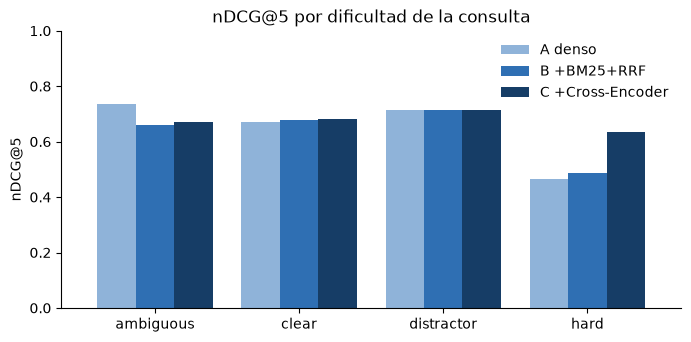

condition,A_dense,B_hybrid_rrf,C_hybrid_rrf_reranker
difficulty,,,
ambiguous,0.737,0.660,0.670
clear,0.672,0.678,0.681
distractor,0.714,0.714,0.714
hard,0.465,0.486,0.634


In [13]:
failure_types = pd.crosstab(per_query["condition"], per_query["failure_type"]).loc[ALL_CONDITIONS]
by_difficulty = per_query[per_query.condition.isin(CONDITIONS)].pivot_table(
    index="difficulty", columns="condition", values=f"ndcg@{NDCG_K}", aggfunc="mean")[CONDITIONS]
display(failure_types)

import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8, 3.6))
by_difficulty.plot.bar(ax=ax, color=["#8fb3d9", "#2f6fb3", "#163d66"], width=0.8)
ax.set_ylabel("nDCG@5"); ax.set_ylim(0, 1); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=0)
ax.set_title("nDCG@5 por dificultad de la consulta"); ax.legend(["A denso", "B +BM25+RRF", "C +Cross-Encoder"], frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()
by_difficulty.round(3)

**Análisis por consulta.** Se buscan las consultas con mayor diferencia de nDCG@5 entre condiciones y se inspeccionan sus rankings. Entre corchetes se muestra el grado de relevancia de cada passage del chunk (0 = no relevante).

In [14]:
deltas1 = per_query.pivot(index="query_id", columns="condition", values=f"ndcg@{NDCG_K}")
deltas1["delta_B_minus_A"] = deltas1["B_hybrid_rrf"] - deltas1["A_dense"]
deltas1["delta_C_minus_B"] = deltas1["C_hybrid_rrf_reranker"] - deltas1["B_hybrid_rrf"]
display(deltas1.round(3).sort_values("delta_C_minus_B"))


def show_rankings(qid: str, conditions=ALL_CONDITIONS, top: int = 4):
    print(f"{qid}: {query_by_id[qid].query}")
    for cond in conditions:
        items = []
        for it in retrieval_runs[(cond, qid)][:top]:
            grades = "".join(str(qrels[qid].get(p, 0)) for p in it["passage_ids"])
            pre = f"(pre{it['pre_rerank_rank']})" if "pre_rerank_rank" in it else ""
            items.append(f"{it['chunk_id']}[{grades}]{pre}")
        print(f"   {cond:22s} nDCG@5={deltas1.loc[qid, cond]:.3f}  " + "  ".join(items))
    print()


for qid in ["Q04", "Q11", "Q15", "Q13"]:
    show_rankings(qid)

condition,A_dense,BM25_only,B_hybrid_rrf,C_hybrid_rrf_reranker,delta_B_minus_A,delta_C_minus_B
query_id,,,,,,
Q11,0.631,1.000,1.000,0.500,0.369,-0.500
Q10,0.613,0.702,0.644,0.613,0.030,-0.030
Q14,0.395,0.117,0.357,0.332,-0.039,-0.024
Q19,0.815,0.834,0.913,0.889,0.098,-0.024
Q18,0.521,0.536,0.536,0.521,0.016,-0.016
Q16,0.700,0.821,0.805,0.805,0.104,0.000
Q15,0.363,0.820,0.820,0.820,0.457,0.000
Q12,0.278,0.351,0.351,0.351,0.073,0.000
Q20,0.631,0.631,0.631,0.631,0.000,0.000


Q04: Are chain-of-thought explanations a faithful account of why the model produced its answer?
   BM25_only              nDCG@5=0.199  2203.11171-C001[00]  2305.04388-C001[0]  2201.11903-C001[0]  2305.04388-C002[2]
   A_dense                nDCG@5=0.845  2305.04388-C004[21]  2201.11903-C001[0]  2305.04388-C002[2]  2201.11903-C002[0]
   B_hybrid_rrf           nDCG@5=0.325  2201.11903-C001[0]  2305.04388-C002[2]  2203.11171-C001[00]  2305.04388-C001[0]
   C_hybrid_rrf_reranker  nDCG@5=0.912  2305.04388-C004[21](pre5)  2305.04388-C001[0](pre4)  2305.04388-C002[2](pre2)  2305.04388-C003[12](pre7)

Q11: Can a much smaller model fine-tuned with human feedback be preferred by humans over a far larger model?
   BM25_only              nDCG@5=1.000  2203.02155-C003[2]  2203.02155-C004[0]  2305.18290-C001[0]  2203.02155-C002[0]
   A_dense                nDCG@5=0.631  2203.02155-C001[0]  2203.02155-C003[2]  2303.03846-C002[0]  2305.14314-C005[00]
   B_hybrid_rrf           nDCG@5=1.000  2203.02155

**Interpretación**

- **Q04** (¿la explicación CoT es fiel?): BM25 coincide con «chain-of-thought» y sube a rank 1 el abstract de Wei et al. (no relevante). RRF lo fusiona y desplaza a Turpin et al. El Cross-Encoder, que lee consulta y passage juntos, devuelve a Turpin a rank 1. Patrón: **coincidencia léxica engañosa**.
- **Q11** (¿un modelo pequeño con RLHF se prefiere a uno grande?): B acierta en rank 1 gracias a «human feedback» + «smaller». El reranker prefiere el passage de DPO («human preferences», RLHF), que es temático pero no responde. **Resultado negativo** del reranker: relevancia temática no es lo mismo que evidencia.
- **Q15** (¿la atención aproximada logra speedup real?): el denso pone primero un passage de FlashAttention sobre atención block-sparse, que es un distractor semántico; BM25 recupera el passage que dice «often do not achieve wall-clock speedup».
- **Q13** es el único `RANKING_ERROR` de B: el único passage directo cae fuera del top-3 y el reranker lo devuelve a rank 1.
- La fusión mejora MRR, pero **empeora Recall@3**: es el único IC95 que no cruza 0. En 5 consultas, los candidatos léxicos desplazan un segundo passage relevante.
- **No se declara superioridad general:** todos los IC95 de nDCG@5 y MRR cruzan 0. El reranker ayuda en las consultas **difíciles**, que son las que contienen dos posturas, a cambio de más de 20 veces la latencia de B (ver la tabla de latencia). Por eso C es la configuración declarada para RAG, con su costo y sus fallos documentados.

In [15]:
per_query.to_csv(OUT1 / "per_query_metrics.csv", index=False)
latency.to_csv(OUT1 / "latency_per_query.csv", index=False)
summary1.round(4).to_csv(OUT1 / "summary.csv")
stage_latency.round(3).to_csv(OUT1 / "latency_by_stage.csv", index=False)
bootstrap1.round(4).to_csv(OUT1 / "bootstrap_paired.csv", index=False)
failure_types.to_csv(OUT1 / "failure_types.csv")
by_difficulty.round(4).to_csv(OUT1 / "ndcg5_by_difficulty.csv")
deltas1.round(4).sort_values("delta_C_minus_B").to_csv(OUT1 / "ndcg5_deltas_per_query.csv")
with (OUT1 / "rankings.jsonl").open("w") as f:
    for (cond, qid), ranked in retrieval_runs.items():
        f.write(json.dumps({"condition": cond, "query_id": qid, "ranking": [
            {"rank": r["rank"], "chunk_id": r["chunk_id"], "passage_ids": r["passage_ids"],
             "score": round(r["score"], 6), "source": r["source"],
             **({"pre_rerank_rank": r["pre_rerank_rank"]} if "pre_rerank_rank" in r else {})}
            for r in ranked]}) + "\n")
(OUT1 / "run_config.json").write_text(json.dumps({
    "executed_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "platform": platform.platform(), "python": platform.python_version(),
    "packages": {p: metadata.version(p) for p in ["torch", "transformers", "sentence-transformers", "faiss-cpu", "rank-bm25"]},
    "device": DEVICE, "dense_model": DENSE_MODEL_ID, "reranker_model": RERANKER_MODEL_ID,
    "faiss_index": "IndexFlatIP", "embedding_dim": retr.dim, "max_chunk_tokens": retr.max_doc_tokens,
    "target_words": TARGET_WORDS, "overlap_passages": OVERLAP_PASSAGES, "candidate_depth": CANDIDATE_DEPTH,
    "rrf_k": RRF_CONSTANT, "bm25": {"k1": BM25_K1, "b": BM25_B, "epsilon": BM25_EPSILON, "tokenizer": BM25_TOKENIZER_VERSION},
    "top_k": TOP_K_VALUES, "ndcg_k": NDCG_K, "seed": SEED, "n_chunks": len(chunks), "n_queries": len(retrieval_qs),
    "sha256": {p.name: sha256_file(p) for p in [CORPUS_PATH, QUERIES_PATH, QRELS_PATH]},
}, indent=2))
print("Resultados del experimento 1 guardados en", OUT1.relative_to(ROOT))

Resultados del experimento 1 guardados en results/exp1


#### **8. Experimento 2 - RAG y evidencia**

**Pregunta:** ¿cambian la corrección y la fidelidad de la respuesta del mismo LLM cuando recibe la evidencia recuperada?

**Variables fijas:** `Qwen/Qwen2.5-0.5B-Instruct`, fp32 en CPU, **greedy** (`do_sample=False`, `repetition_penalty=1.0`), `max_new_tokens=220`, las mismas 12 preguntas fijadas antes de ejecutar (10 con respuesta y 2 donde corresponde abstenerse), el mismo contrato JSON.
**Modificación:** el prompt RAG incluye los passages de los top-3 chunks de la **condición C**, cada uno con su `passage_id`. El closed-book recibe solo la pregunta.

Los prompts están versionados en `prompts/` y se validan en tres niveles, igual que en PC1: `raw_json` → `recovered_json` (sin el bloque de código) → `schema_valid`; luego viene la validación semántica de las citas.

In [16]:
def load_prompt(name: str) -> str:
    return (PROMPTS_DIR / name).read_text()


for name in ["rag_system.txt", "rag_user.txt"]:
    print(f"----- prompts/{name} -----\n{load_prompt(name)}")

----- prompts/rag_system.txt -----
Eres un Auditor de Literatura Científica. Determinas si varios artículos coinciden o discrepan sobre una afirmación, usando ÚNICAMENTE los pasajes de evidencia proporcionados.

[REGLAS]
1. Usa solo la información de los pasajes. No uses conocimiento previo.
2. Cada afirmación de tu respuesta debe estar respaldada por un pasaje citado por su identificador exacto, por ejemplo "2001.08361-P03".
3. Cita únicamente identificadores que aparezcan en la evidencia.
4. Si los pasajes no contienen evidencia suficiente para responder, usa relation = "insufficient_evidence" y citations = [].
5. Escribe el campo answer en inglés, el idioma de los artículos, en 1-3 oraciones.

[RELACIONES]
- "disagree": los artículos reportan hallazgos o conclusiones incompatibles sobre la pregunta.
- "agree": los artículos respaldan la misma conclusión.
- "neutral": abordan aspectos complementarios sin contradecirse.
- "insufficient_evidence": la evidencia no permite responder.

[C

In [17]:
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer


def build_context(ranked_chunks: list[dict], top_k: int = RAG_TOP_K):
    ids, blocks = [], []
    for chunk in ranked_chunks[:top_k]:
        for pid in chunk["passage_ids"]:
            if pid in ids:
                continue
            ids.append(pid)
            p = passages_by_id[pid]
            blocks.append(f'[{pid}] ({p["title"]}, {p["year"]})\n{p["text"]}')
    return "\n\n".join(blocks), ids


def parse_json_object(text: str):
    text = text.strip()
    try:
        value = json.loads(text)
        return (value, "raw_json") if isinstance(value, dict) else (None, "unparseable")
    except json.JSONDecodeError:
        match = re.search(r"\{.*\}", text, flags=re.DOTALL)
        if match:
            try:
                value = json.loads(match.group(0))
                if isinstance(value, dict):
                    return value, "recovered_json"
            except json.JSONDecodeError:
                pass
    return None, "unparseable"


def validate_output(raw_output: str, context_ids: list[str]) -> dict:
    obj, level = parse_json_object(raw_output)
    result = {"parse_level": level, "schema_valid": False, "semantic_problems": [], "parsed": obj}
    if obj is None:
        return result
    try:
        answer = RAGAnswer.model_validate(obj)
    except ValidationError as exc:
        result["schema_error"] = str(exc).splitlines()[0]
        return result
    result.update(schema_valid=True, parsed=answer.model_dump(mode="json"),
                  semantic_problems=semantic_check(answer, set(context_ids)))
    return result


class Generator:
    def __init__(self):
        torch.manual_seed(SEED)
        self.tokenizer = AutoTokenizer.from_pretrained(GENERATOR_MODEL_ID)
        self.model = AutoModelForCausalLM.from_pretrained(GENERATOR_MODEL_ID, dtype=torch.float32).to(DEVICE).eval()
        self.context_window = self.model.config.max_position_embeddings

    def generate(self, system: str, user: str) -> dict:
        messages = [{"role": "system", "content": system}, {"role": "user", "content": user}]
        prompt = self.tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
        inputs = self.tokenizer(prompt, return_tensors="pt").to(DEVICE)
        n_prompt = int(inputs["input_ids"].shape[1])
        if n_prompt + MAX_NEW_TOKENS > self.context_window:
            raise ValueError(f"El prompt no cabe en la ventana de contexto: {n_prompt} tokens")
        start = time.perf_counter()
        with torch.no_grad():
            out = self.model.generate(**inputs, max_new_tokens=MAX_NEW_TOKENS, do_sample=DO_SAMPLE,
                                      temperature=None, top_p=None, top_k=None,
                                      repetition_penalty=REPETITION_PENALTY,
                                      pad_token_id=self.tokenizer.eos_token_id)
        new_tokens = out[0][n_prompt:]
        return {"raw_output": self.tokenizer.decode(new_tokens, skip_special_tokens=True),
                "prompt_tokens": n_prompt, "generated_tokens": int(len(new_tokens)),
                "generation_ms": (time.perf_counter() - start) * 1000.0}


assert parse_json_object('```json\n{"a": 1}\n```') == ({"a": 1}, "recovered_json")
gen = Generator()
print(f"{GENERATOR_MODEL_ID} cargado · ventana de contexto {gen.context_window} tokens")

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Loading weights:   0%|          | 1/290 [00:02<14:07,  2.93s/it]

Loading weights: 100%|██████████| 290/290 [00:02<00:00, 98.47it/s]

Qwen/Qwen2.5-0.5B-Instruct cargado · ventana de contexto 32768 tokens


In [18]:
OUT2 = RESULTS_DIR / "exp2"
OUT2.mkdir(parents=True, exist_ok=True)
PROMPTS = {"rag": (load_prompt("rag_system.txt"), load_prompt("rag_user.txt")),
           "closed_book": (load_prompt("closed_book_system.txt"), load_prompt("closed_book_user.txt"))}

gen_rows = []
for qid in RAG_QUERY_IDS:
    q = query_by_id[qid]
    runs, _ = retr.run_all(q.query)
    context, context_ids = build_context(runs[RAG_CONDITION])
    for mode, (system, user_t) in PROMPTS.items():
        user = user_t.format(query=q.query, context=context) if mode == "rag" else user_t.format(query=q.query)
        g = gen.generate(system, user)
        v = validate_output(g["raw_output"], context_ids if mode == "rag" else [])
        parsed = v["parsed"] if v["schema_valid"] else None
        pred = parsed["relation"] if parsed else None
        cits = parsed["citations"] if parsed else []
        gen_rows.append({
            "query_id": qid, "mode": mode, "difficulty": q.difficulty.value, "query": q.query,
            "gold_relation": references[qid]["gold_relation"], "pred_relation": pred,
            "relation_correct": pred == references[qid]["gold_relation"],
            "abstained": pred == "insufficient_evidence",
            **{k: v[k] for k in ["parse_level", "schema_valid", "semantic_problems"]},
            "answer": parsed["answer"] if parsed else None, "citations": cits,
            "confidence": parsed["confidence"] if parsed else None,
            **citation_metrics(cits, set(context_ids) if mode == "rag" else set(), qrels[qid]),
            "context_passage_ids": context_ids if mode == "rag" else [],
            "gold_in_context": sorted(set(context_ids) & set(qrels[qid])) if mode == "rag" else [],
            **{k: g[k] for k in ["prompt_tokens", "generated_tokens", "generation_ms"]},
            "raw_output": g["raw_output"]})

gen_df = pd.DataFrame(gen_rows)
with (OUT2 / "generations.jsonl").open("w") as f:
    for r in gen_rows:
        f.write(json.dumps(r, ensure_ascii=False) + "\n")
gen_df[["query_id", "mode", "gold_relation", "pred_relation", "parse_level", "schema_valid", "citations"]]

,query_id,mode,gold_relation,pred_relation,parse_level,schema_valid,citations
0,Q01,rag,disagree,agree,raw_json,True,"[2001.08361-P01, 2001.08361-P02, 2203.15556-P02, 2203.15556-P01]"
1,Q01,closed_book,disagree,NaN,raw_json,False,[]
2,Q02,rag,disagree,NaN,raw_json,False,[]
3,Q02,closed_book,disagree,neutral,raw_json,True,[]
4,Q07,rag,agree,agree,raw_json,True,"[2312.05934-P02, 2312.05934-P03, 2312.05934-P01, 2312.05934-P04]"
5,Q07,closed_book,agree,NaN,raw_json,False,[]
6,Q09,rag,agree,agree,raw_json,True,"[1911.02150-P02, 2305.13245-P01, 2305.13245-P02]"
7,Q09,closed_book,agree,NaN,raw_json,False,[]
8,Q10,rag,disagree,NaN,recovered_json,False,[]
9,Q10,closed_book,disagree,NaN,raw_json,False,[]


In [19]:
auto2 = gen_df.groupby("mode").agg(
    n=("query_id", "count"), schema_valid_rate=("schema_valid", "mean"),
    relation_accuracy=("relation_correct", "mean"), abstention_rate=("abstained", "mean"),
    citation_in_context_rate=("citation_in_context_rate", "mean"),
    citation_support_rate=("citation_support_rate", "mean"),
    semantic_problem_rate=("semantic_problems", lambda s: (s.str.len() > 0).mean()),
    generation_ms_mean=("generation_ms", "mean"), prompt_tokens_mean=("prompt_tokens", "mean"))
auto2.round(4).to_csv(OUT2 / "auto_summary.csv")
(OUT2 / "run_config.json").write_text(json.dumps({
    "generator": GENERATOR_MODEL_ID, "device": DEVICE, "dtype": "float32",
    "decoding": {"do_sample": DO_SAMPLE, "max_new_tokens": MAX_NEW_TOKENS, "repetition_penalty": REPETITION_PENALTY},
    "context_window": gen.context_window, "retrieval_condition": RAG_CONDITION, "rag_top_k_chunks": RAG_TOP_K,
    "query_ids": RAG_QUERY_IDS, "seed": SEED,
    "sha256": {p.name: sha256_file(p) for p in sorted(PROMPTS_DIR.glob("*.txt"))}}, indent=2))

rag_rows = gen_df[gen_df["mode"] == "rag"]
answerable = rag_rows[rag_rows.gold_relation != "insufficient_evidence"]
print(f"Preguntas con respuesta cuyo gold llegó al contexto: {(answerable.gold_in_context.str.len() > 0).sum()}/{len(answerable)}")
print(f"Relación 'agree' en el raw_output de RAG: "
      f"{sum(re.search(r'\"relation\":\s*\"agree\"', r) is not None for r in rag_rows.raw_output)}/{len(rag_rows)}")
auto2.round(3)

Preguntas con respuesta cuyo gold llegó al contexto: 10/10
Relación 'agree' en el raw_output de RAG: 12/12


,n,schema_valid_rate,relation_accuracy,abstention_rate,citation_in_context_rate,citation_support_rate,semantic_problem_rate,generation_ms_mean,prompt_tokens_mean
mode,,,,,,,,,
closed_book,12,0.250,0.00,0.0,NaN,NaN,0.0,1334.030,271.667
rag,12,0.833,0.25,0.0,1.0,0.385,0.0,4883.664,789.083


**Auditoría manual (no se usa un LLM como juez).** Cada respuesta se descompone en **afirmaciones atómicas** y se evalúan por separado tres cosas:

| Dimensión | Pregunta | Escala |
|---|---|---|
| **Corrección** | ¿La respuesta coincide con `reference_answers.jsonl` (relación + hechos clave)? | correct = 1, partial = 0,5, incorrect = 0 |
| **Citas** | ¿Los passages citados respaldan lo que se afirma? | 1 todas, 0,5 alguna y ninguna contradice, 0 alguna contradice o no hay citas |
| **Faithfulness** | ¿Cada afirmación está sustentada por el contexto (en RAG) o por el corpus (en closed-book)? | supported / unsupported / contradicted |

Las respuestas que no cumplen el schema se auditan igualmente por su contenido. El protocolo y los 24 veredictos con su justificación están en `results/exp2/manual_audit.json`.

In [20]:
audit = json.loads((OUT2 / "manual_audit.json").read_text())
assert audit["protocol"]["run"].startswith("results/exp2/generations.jsonl")
audit_rows = []
for item in audit["items"]:
    supported = sum(c["verdict"] == "supported" for c in item["claims"])
    audit_rows.append({"query_id": item["query_id"], "mode": item["mode"],
                       "answer_correctness": item["answer_correctness"], "citation_score": item["citation_score"],
                       "n_claims": len(item["claims"]), "supported_claims": supported,
                       "faithfulness": supported / len(item["claims"]) if item["claims"] else None})
audit_df = pd.DataFrame(audit_rows)
audit_df.to_csv(OUT2 / "manual_audit_per_item.csv", index=False)
audit_df["correctness_score"] = audit_df["answer_correctness"].map({"correct": 1.0, "partial": 0.5, "incorrect": 0.0})
manual2 = audit_df.groupby("mode").agg(
    answer_correctness=("correctness_score", "mean"),
    fully_correct=("answer_correctness", lambda s: (s == "correct").mean()),
    citation_score=("citation_score", lambda s: s.dropna().astype(float).mean()),
    total_claims=("n_claims", "sum"), supported_claims=("supported_claims", "sum"))
manual2["faithfulness_micro"] = manual2["supported_claims"] / manual2["total_claims"]
manual2.round(4).to_csv(OUT2 / "manual_audit_summary.csv")
manual2.round(3)

,answer_correctness,fully_correct,citation_score,total_claims,supported_claims,faithfulness_micro
mode,,,,,,
closed_book,0.083,0.000,NaN,7,1,0.143
rag,0.250,0.167,0.208,19,12,0.632


In [21]:
def show_audit(qid: str, mode: str = "rag"):
    g = next(r for r in gen_rows if r["query_id"] == qid and r["mode"] == mode)
    a = next(i for i in audit["items"] if i["query_id"] == qid and i["mode"] == mode)
    print(f"{qid} [{mode}] {g['query']}\n  contexto: {g['context_passage_ids']}\n  salida:   {g['raw_output'].strip()[:400]}")
    for c in a["claims"]:
        print(f"  - [{c['verdict']}] {c['claim']}  <- {c['evidence']}")
    print(f"  corrección={a['answer_correctness']} · citas={a['citation_score']}\n  nota: {a['note']}\n")


for qid, mode in [("Q17", "rag"), ("Q21", "rag"), ("Q09", "rag"), ("Q07", "closed_book")]:
    show_audit(qid, mode)

Q17 [rag] Do dense retrievers outperform BM25, especially in zero-shot settings?
  contexto: ['2104.08663-P03', '2104.08663-P04', '2104.08663-P02', '2004.04906-P02']
  salida:   {"relation": "agree", "answer": "The dense retriever outperforms BM25, especially in zero-shot settings.", "citations": ["2104.08663-P03", "2104.08663-P04", "2104.08663-P02", "2004.04906-P02"], "confidence": 1.0}
  - [supported] Dense retrievers outperform BM25  <- 2004.04906-P02 (en dominio)
  - [contradicted] ...especially in zero-shot settings  <- 2104.08663-P03
  corrección=incorrect · citas=0.0
  nota: Caso más claro de infidelidad: la primera cita (BEIR P03) dice lo contrario de la parte zero-shot. El modelo sigue su prior, no la evidencia.

Q21 [rag] Do state space models such as Mamba outperform Transformers on language modeling?
  contexto: ['2006.04768-P01', '2006.04768-P02', '2210.17323-P01', '1706.03762-P03', '1706.03762-P04']
  salida:   ```json
{"relation": "agree", "answer": "state space models s

**Errores y respuestas no sustentadas**

- **Q17, cita que contradice la respuesta:** «dense outperforms BM25, especially zero-shot», citando a BEIR, que dice lo contrario para zero-shot.
- **Abstención 0 de 2:** con Mamba (Q21) cita 5 passages irrelevantes; con Llama 3 (Q22), el distractor «Chinchilla» lo desvía.
- **Alucinación bibliográfica (Q07, closed-book):** inventa «Zhang & Li (2020), JAIR 64».
- **Sesgo de etiqueta:** RAG responde `agree` en todas las preguntas. El modelo lo interpreta como «sí a la pregunta», no como «los artículos coinciden».
- **Citas en bloque:** el 100 % de las citas está dentro del contexto, pero solo una fracción apunta a passages relevantes. La métrica automática «en contexto» no basta como evidencia de grounding.

**Diagnóstico:** el gold estuvo en el contexto en todas las preguntas con respuesta. **El cuello de botella es la generación, no la recuperación.**

**Corrida previa conservada** (`results/exp2_run0_repetition_penalty/`): se hizo con el `repetition_penalty=1.1` oculto del `generation_config.json` de Qwen. El hallazgo se explica en la sección 9. Se corrigió para que el decoding declarado (greedy) fuera el ejecutado, y se re-ejecutó una sola vez con las mismas preguntas.

**Conclusión:** RAG mejora la validez del schema, la corrección y la fidelidad frente a closed-book, pero con un modelo de 0,5B no produce respuestas confiables. Separar corrección, citas y faithfulness muestra fallos que una métrica de fluidez o de «citas en contexto» ocultaría.

#### **9. Inspección del modelo (Semanas 1 y 2)**

Evidencia sobre el **mismo** modelo del experimento 2:

1. **Arquitectura:** capas, HEADs de Query y de Key/Value (GQA), dimensión por HEAD, RoPE, ventana de contexto.
2. **Tokenización y máscara causal:** en una frase del dominio, la atención sobre posiciones futuras debe ser 0 y cada fila debe sumar 1 tras el softmax.
3. **Logits → softmax** del primer token generado con el prompt RAG real de Q17: justifica el greedy y revela el `repetition_penalty`.
4. **KV cache:** $2 \times capas \times HEADs_{KV} \times d_{head} \times bytes$ por token, comparado con multi-head attention.

Se carga con `attn_implementation="eager"` porque `sdpa` no devuelve las matrices de atención.

In [22]:
insp_tok = AutoTokenizer.from_pretrained(GENERATOR_MODEL_ID)
insp_model = AutoModelForCausalLM.from_pretrained(GENERATOR_MODEL_ID, dtype=torch.float32,
                                                  attn_implementation="eager").eval()
cfg = insp_model.config
head_dim = cfg.hidden_size // cfg.num_attention_heads
rope_theta = (getattr(cfg, "rope_parameters", None) or {}).get("rope_theta", getattr(cfg, "rope_theta", None))

# Tokenización y máscara causal
text = "Chinchilla disagrees with Kaplan."
ids = insp_tok(text, return_tensors="pt")
with torch.no_grad():
    att = insp_model(**ids, output_attentions=True).attentions[0][0, 0]  # capa 0, HEAD 0
above_diag = float(torch.triu(att, diagonal=1).abs().max())
assert above_diag == 0.0 and torch.allclose(att.sum(-1), torch.ones(att.shape[0]))
print("Tokens:", insp_tok.convert_ids_to_tokens(ids["input_ids"][0]))
print(f"Máscara causal: atención máxima sobre la diagonal = {above_diag} · filas suman 1: OK")
pd.DataFrame(att.numpy().round(3), index=insp_tok.convert_ids_to_tokens(ids["input_ids"][0]),
             columns=insp_tok.convert_ids_to_tokens(ids["input_ids"][0]))

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Loading weights:   0%|          | 1/290 [00:03<17:47,  3.69s/it]

Loading weights: 100%|██████████| 290/290 [00:03<00:00, 78.41it/s]

Tokens: ['Ch', 'inch', 'illa', 'Ġdisagrees', 'Ġwith', 'ĠKaplan', '.']
Máscara causal: atención máxima sobre la diagonal = 0.0 · filas suman 1: OK


,Ch,inch,illa,Ġdisagrees,Ġwith,ĠKaplan,.
Ch,1.000,0.000,0.000,0.000,0.000,0.000,0.000
inch,0.503,0.497,0.000,0.000,0.000,0.000,0.000
illa,0.296,0.335,0.369,0.000,0.000,0.000,0.000
Ġdisagrees,0.247,0.204,0.203,0.346,0.000,0.000,0.000
Ġwith,0.213,0.200,0.167,0.286,0.134,0.000,0.000
ĠKaplan,0.113,0.088,0.078,0.169,0.124,0.427,0.000
.,0.064,0.047,0.042,0.157,0.285,0.254,0.151


In [23]:
# Logits del primer token (prompt RAG de Q17)
g17 = next(r for r in gen_rows if r["query_id"] == "Q17" and r["mode"] == "rag")
context17, _ = build_context([{"passage_ids": g17["context_passage_ids"]}], top_k=1)
msgs = [{"role": "system", "content": load_prompt("rag_system.txt")},
        {"role": "user", "content": load_prompt("rag_user.txt").format(query=g17["query"], context=context17)}]
prompt17 = insp_tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
inputs17 = insp_tok(prompt17, return_tensors="pt")
assert int(inputs17["input_ids"].shape[1]) == g17["prompt_tokens"]
with torch.no_grad():
    logits = insp_model(**inputs17).logits[0, -1]
probs = torch.softmax(logits, dim=-1)
top = torch.topk(probs, 5)
first_tokens = pd.DataFrame({"token": [repr(insp_tok.decode([int(i)])) for i in top.indices],
                             "logit": [round(float(logits[i]), 3) for i in top.indices],
                             "prob": [round(float(p), 4) for p in top.values]})
display(first_tokens)

with open(next((Path.home() / ".cache/huggingface/hub/models--Qwen--Qwen2.5-0.5B-Instruct/snapshots").glob("*")) / "generation_config.json") as f:
    print("generation_config.json de Qwen:", json.load(f))
print("\nGreedy elegiría:", repr(insp_tok.decode([int(top.indices[0])])))
print("generate() con repetition_penalty=1.0 empezó con:", repr(g17["raw_output"][:12]))
print("La corrida previa (repetition_penalty=1.1) empezaba con un bloque de código json: la penalización "
      "castiga los tokens que ya aparecen en el prompt, incluido el '{\"' del contrato.")

,token,logit,prob
0,"'{""'",27.177,0.7735
1,'```',25.739,0.1837
2,'{\n',24.245,0.0412
3,'``',20.413,0.0009
4,'{',18.477,0.0001


generation_config.json de Qwen: {'bos_token_id': 151643, 'pad_token_id': 151643, 'do_sample': True, 'eos_token_id': [151645, 151643], 'repetition_penalty': 1.1, 'temperature': 0.7, 'top_p': 0.8, 'top_k': 20, 'transformers_version': '4.37.0'}

Greedy elegiría: '{"'
generate() con repetition_penalty=1.0 empezó con: '{"relation":'
La corrida previa (repetition_penalty=1.1) empezaba con un bloque de código json: la penalización castiga los tokens que ya aparecen en el prompt, incluido el '{"' del contrato.


In [24]:
# KV cache por token
bytes_fp32 = 4
kv_gqa = 2 * cfg.num_hidden_layers * cfg.num_key_value_heads * head_dim * bytes_fp32
kv_mha = 2 * cfg.num_hidden_layers * cfg.num_attention_heads * head_dim * bytes_fp32
longest = max(r["prompt_tokens"] + r["generated_tokens"] for r in gen_rows)

inspection = {
    "model": GENERATOR_MODEL_ID, "architecture": "decoder-only causal transformer",
    "num_hidden_layers": cfg.num_hidden_layers, "hidden_size": cfg.hidden_size,
    "num_attention_heads_q": cfg.num_attention_heads, "num_key_value_heads": cfg.num_key_value_heads,
    "head_dim": head_dim, "attention_variant": "GQA (grouped-query attention)",
    "queries_per_kv_head": cfg.num_attention_heads // cfg.num_key_value_heads,
    "position_encoding": f"RoPE (rope_theta={rope_theta})", "context_window": cfg.max_position_embeddings,
    "vocab_size": cfg.vocab_size, "parameters": sum(p.numel() for p in insp_model.parameters()),
    "tokenization_example": {"text": text, "tokens": insp_tok.convert_ids_to_tokens(ids["input_ids"][0])},
    "causal_mask_check": {"seq_len": int(att.shape[0]), "max_attention_above_diagonal": above_diag},
    "first_token_greedy_choice_Q17": insp_tok.decode([int(top.indices[0])]),
    "first_token_distribution_Q17": [{"token": insp_tok.decode([int(i)]), "prob": round(float(p), 4)}
                                     for p, i in zip(top.values, top.indices)],
    "kv_cache": {"bytes_per_token_fp32_gqa": kv_gqa, "bytes_per_token_fp32_if_mha": kv_mha,
                 "reduction_factor": kv_mha / kv_gqa, "longest_sequence_exp2_tokens": longest,
                 "mb_for_longest_sequence": round(kv_gqa * longest / 1e6, 2)},
}
(RESULTS_DIR / "model_inspection.json").write_text(json.dumps(inspection, indent=2, ensure_ascii=False))
print(f"Qwen2.5-0.5B: {cfg.num_hidden_layers} capas · {cfg.num_attention_heads} HEADs Q · "
      f"{cfg.num_key_value_heads} HEADs K/V (GQA, {cfg.num_attention_heads // cfg.num_key_value_heads} Q por K/V) · "
      f"head_dim {head_dim} · {inspection['parameters']/1e6:.0f} M parámetros")
print(f"KV cache: {kv_gqa:,} bytes/token con GQA vs {kv_mha:,} con MHA ({kv_mha // kv_gqa}x) · "
      f"secuencia más larga {longest} tokens -> {kv_gqa * longest / 1e6:.1f} MB de {cfg.max_position_embeddings} posiciones posibles")
del insp_model

Qwen2.5-0.5B: 24 capas · 14 HEADs Q · 2 HEADs K/V (GQA, 7 Q por K/V) · head_dim 64 · 494 M parámetros
KV cache: 24,576 bytes/token con GQA vs 172,032 con MHA (7x) · secuencia más larga 1030 tokens -> 25.3 MB de 32768 posiciones posibles


#### **10. Experimento 3 - Herramienta con contratos (Semana 6)**

**Herramienta:** `citation.check_temporal_validity(citing_id, cited_id)`. Verifica con el catálogo local (fechas de arXiv) si una cita es **temporalmente posible**: un artículo no puede citar a otro publicado después que él. Es la verificación determinista del campo `citation_valid` que en PC1 decidía el LLM.

Flujo de ejecución:

```text
ToolCall {name, arguments}
-> análisis sintáctico (parsing)
-> lista de herramientas permitidas (allowlist)       -> protocol
-> contrato de entrada (Pydantic, extra=forbid)       -> validation
-> validación de dominio (existe, no es autocita)     -> domain
-> política de ejecución
     +-> timeout por intento (100 ms)                 -> timeout   (retryable)
     +-> reintento selectivo (máx. 3 intentos)        -> transient (retryable)
     +-> backoff (20 / 40 ms) y deadline total (400 ms)
-> contrato de salida (invariante de fechas)          -> output_contract
-> ToolResult {status, data | error}
```

`fault` es un parámetro del experimento para inyectar fallos; no forma parte de la interfaz pública.

In [25]:
TOOL_NAME = "citation.check_temporal_validity"
ARXIV_ID_PATTERN = r"^\d{4}\.\d{4,5}$"


class CheckCitationInput(BaseModel):
    model_config = {"extra": "forbid"}
    citing_id: str = Field(pattern=ARXIV_ID_PATTERN)
    cited_id: str = Field(pattern=ARXIV_ID_PATTERN)


class CheckCitationOutput(BaseModel):
    citing_id: str
    cited_id: str
    citing_date: date
    cited_date: date
    days_between: int
    temporally_valid: bool

    @model_validator(mode="after")
    def consistent(self):
        if self.temporally_valid != (self.cited_date <= self.citing_date):
            raise ValueError("temporally_valid inconsistente con las fechas")
        return self


ErrorKind = Literal["protocol", "validation", "domain", "transient", "timeout", "execution", "output_contract"]


class ToolError(BaseModel):
    code: str
    kind: ErrorKind
    retryable: bool
    message: str


class ToolResult(BaseModel):
    status: Literal["ok", "error"]
    data: dict[str, Any] | None = None
    error: ToolError | None = None


def error_result(kind, code, message, retryable) -> ToolResult:
    return ToolResult(status="error", error=ToolError(code=code, kind=kind, retryable=retryable, message=message))


class DomainError(Exception):
    def __init__(self, code: str, message: str):
        super().__init__(message)
        self.code = code


class TransientToolError(Exception):
    pass


CATALOG = {p["arxiv_id"]: date.fromisoformat(p["published"]) for p in raw["papers"]}


def validate_domain(args: CheckCitationInput) -> None:
    if args.citing_id == args.cited_id:
        raise DomainError("self_citation", "Un artículo no puede citarse a sí mismo en esta verificación.")
    for field in ("citing_id", "cited_id"):
        if getattr(args, field) not in CATALOG:
            raise DomainError("unknown_paper", f"{field}={getattr(args, field)} no existe en el catálogo local.")


async def check_temporal_validity(args: CheckCitationInput, fault: str, attempt: int) -> dict:
    if fault == "transient_once" and attempt == 1:
        raise TransientToolError("Catálogo temporalmente no disponible.")
    if fault == "slow_always" or (fault == "slow_once" and attempt == 1):
        await asyncio.sleep(0.5)
    if fault == "bad_output":
        return {"citing_id": args.citing_id, "valid": "unknown"}
    citing, cited = CATALOG[args.citing_id], CATALOG[args.cited_id]
    return {"citing_id": args.citing_id, "cited_id": args.cited_id, "citing_date": citing.isoformat(),
            "cited_date": cited.isoformat(), "days_between": (citing - cited).days, "temporally_valid": cited <= citing}


TOOL_IMPLS = {TOOL_NAME: check_temporal_validity}
print(f"Catálogo local: {len(CATALOG)} artículos · herramientas permitidas: {list(TOOL_IMPLS)}")

Catálogo local: 36 artículos · herramientas permitidas: ['citation.check_temporal_validity']


In [26]:
@dataclass(frozen=True)
class Policy:
    max_attempts: int = 3
    backoff_ms: tuple[int, ...] = (20, 40)
    per_attempt_timeout_ms: int = 100
    overall_deadline_ms: int = 400


def exception_to_tool_error(exc: BaseException) -> ToolError:
    # Se clasifica por tipo de excepción
    if isinstance(exc, DomainError):
        return ToolError(code=exc.code, kind="domain", retryable=False, message=str(exc))
    if isinstance(exc, TransientToolError):
        return ToolError(code="temporary_unavailable", kind="transient", retryable=True, message=str(exc))
    if isinstance(exc, asyncio.TimeoutError):
        return ToolError(code="attempt_timeout", kind="timeout", retryable=True, message="Intento excedió el timeout.")
    return ToolError(code="execution_error", kind="execution", retryable=False, message=repr(exc))


def should_retry(error: ToolError, attempt: int, max_attempts: int) -> bool:
    # Solo se reintentan errores transitorios y timeouts
    return error.retryable and attempt < max_attempts


def remaining_budget_ms(started: float, overall_deadline_ms: float) -> float:
    return max(0.0, overall_deadline_ms - (time.perf_counter() - started) * 1000.0)


def can_backoff(remaining_ms: float, backoff_ms: float) -> bool:
    return remaining_ms > backoff_ms


def parse_tool_call(raw_call: str):
    try:
        call = json.loads(raw_call)
        name, arguments = call["name"], call["arguments"]
        if not isinstance(arguments, dict):
            raise TypeError("arguments debe ser un objeto")
    except (json.JSONDecodeError, KeyError, TypeError) as exc:
        return error_result("protocol", "malformed_tool_call", str(exc), False)
    if name not in TOOL_IMPLS:
        return error_result("protocol", "unknown_tool", f"Tool no permitida: {name}", False)
    return name, arguments


async def execute(raw_call: str, fault: str = "none", policy: Policy = Policy()) -> dict:
    started = time.perf_counter()
    traces = []

    def finish(result: ToolResult, attempts: int) -> dict:
        return {"result": result.model_dump(mode="json"), "attempts": attempts,
                "latency_ms": round((time.perf_counter() - started) * 1000.0, 2), "traces": traces}

    parsed = parse_tool_call(raw_call)
    if isinstance(parsed, ToolResult):
        return finish(parsed, 0)
    name, raw_args = parsed
    try:
        args = CheckCitationInput.model_validate(raw_args)
    except ValidationError as exc:
        err = exc.errors()[0]
        return finish(error_result("validation", "invalid_arguments",
                                   f"{'.'.join(map(str, err['loc']))}: {err['msg']}", False), 0)
    try:
        validate_domain(args)
    except DomainError as exc:
        return finish(ToolResult(status="error", error=exception_to_tool_error(exc)), 0)

    attempt = 0
    while True:
        attempt += 1
        t0 = time.perf_counter()
        remaining = remaining_budget_ms(started, policy.overall_deadline_ms)
        if remaining <= 0:
            return finish(error_result("timeout", "deadline_exceeded", "Deadline total agotado.", True), attempt - 1)
        try:
            data = await asyncio.wait_for(TOOL_IMPLS[name](args, fault, attempt),
                                          timeout=min(policy.per_attempt_timeout_ms, remaining) / 1000.0)
        except Exception as exc:
            error = exception_to_tool_error(exc)
            traces.append({"attempt": attempt, "status": "error", "error_kind": error.kind,
                           "latency_ms": round((time.perf_counter() - t0) * 1000.0, 2)})
            if not should_retry(error, attempt, policy.max_attempts):
                return finish(ToolResult(status="error", error=error), attempt)
            backoff = policy.backoff_ms[min(attempt - 1, len(policy.backoff_ms) - 1)]
            if not can_backoff(remaining_budget_ms(started, policy.overall_deadline_ms), backoff):
                return finish(error_result("timeout", "deadline_exceeded",
                                           "No queda presupuesto para backoff y otro intento.", True), attempt)
            await asyncio.sleep(backoff / 1000.0)
            continue
        try:
            data = CheckCitationOutput.model_validate(data).model_dump(mode="json")
        except ValidationError:
            traces.append({"attempt": attempt, "status": "error", "error_kind": "output_contract",
                           "latency_ms": round((time.perf_counter() - t0) * 1000.0, 2)})
            return finish(error_result("output_contract", "invalid_tool_output", "La salida viola el contrato.", False), attempt)
        traces.append({"attempt": attempt, "status": "ok", "error_kind": None,
                       "latency_ms": round((time.perf_counter() - t0) * 1000.0, 2)})
        return finish(ToolResult(status="ok", data=data), attempt)


# Pruebas de la política
t_err = exception_to_tool_error(TransientToolError("x"))
d_err = exception_to_tool_error(DomainError("unknown_paper", "x"))
assert should_retry(t_err, 1, 3) and not should_retry(t_err, 3, 3) and not should_retry(d_err, 1, 3)
assert exception_to_tool_error(asyncio.TimeoutError()).kind == "timeout"
assert can_backoff(30, 20) and not can_backoff(10, 20)
print("Política de retry: OK")

Política de retry: OK


In [27]:
def call(citing: str, cited: str, **extra) -> str:
    return json.dumps({"name": TOOL_NAME, "arguments": {"citing_id": citing, "cited_id": cited, **extra}})


TOOL_CASES = [
    ("T01", "válida: Chinchilla (2022) cita a Kaplan (2020)", call("2203.15556", "2001.08361"), "none", "ok"),
    ("T02", "válida con veredicto negativo: Kaplan no puede citar a Chinchilla", call("2001.08361", "2203.15556"), "none", "ok"),
    ("T03", "entrada inválida: formato de ID", call("Chinchilla", "2001.08361"), "none", "validation"),
    ("T04", "entrada inválida: campo extra no permitido", call("2203.15556", "2001.08361", year=2022), "none", "validation"),
    ("T05", "error de dominio: artículo fuera del catálogo", call("2203.15556", "2401.04088"), "none", "domain"),
    ("T06", "error de dominio: autocita", call("2203.15556", "2203.15556"), "none", "domain"),
    ("T07", "fallo transitorio una vez -> retry exitoso", call("2305.18290", "2203.02155"), "transient_once", "ok"),
    ("T08", "timeout una vez -> retry exitoso", call("2305.18290", "2203.02155"), "slow_once", "ok"),
    ("T09", "timeout persistente -> deadline agotado", call("2305.18290", "2203.02155"), "slow_always", "timeout"),
    ("T10", "salida que viola el contrato", call("2305.18290", "2203.02155"), "bad_output", "output_contract"),
    ("T11", "herramienta no permitida (allowlist)", json.dumps({"name": "citation.delete_paper", "arguments": {}}), "none", "protocol"),
    ("T12", "ToolCall mal formada", '{"name": "citation.check_temporal_validity"', "none", "protocol"),
]

OUT3 = RESULTS_DIR / "exp3"
OUT3.mkdir(parents=True, exist_ok=True)
tool_rows = []
with (OUT3 / "traces.jsonl").open("w") as f:
    for cid, desc, raw_call, fault, expected in TOOL_CASES:
        out = await execute(raw_call, fault=fault)
        res = out["result"]
        observed = "ok" if res["status"] == "ok" else res["error"]["kind"]
        f.write(json.dumps({"case_id": cid, "description": desc, "fault": fault, "raw_call": raw_call,
                            "expected": expected, "observed": observed, **out}, ensure_ascii=False) + "\n")
        tool_rows.append({"case_id": cid, "description": desc, "fault": fault, "expected": expected,
                          "observed": observed, "match": expected == observed,
                          "error_code": res["error"]["code"] if res["error"] else None,
                          "retryable": res["error"]["retryable"] if res["error"] else None,
                          "temporally_valid": res["data"]["temporally_valid"] if res["data"] else None,
                          "attempts": out["attempts"], "latency_ms": out["latency_ms"]})
tool_df = pd.DataFrame(tool_rows)
tool_df.to_csv(OUT3 / "summary.csv", index=False)
assert tool_df.match.all()
print(f"Casos que coinciden con lo esperado: {int(tool_df.match.sum())}/{len(tool_df)}")
tool_df.drop(columns=["description"])

Casos que coinciden con lo esperado: 12/12


,case_id,fault,expected,observed,match,error_code,retryable,temporally_valid,attempts,latency_ms
0,T01,none,ok,ok,True,NaN,None,True,1,0.56
1,T02,none,ok,ok,True,NaN,None,False,1,0.02
2,T03,none,validation,validation,True,invalid_arguments,False,None,0,0.08
3,T04,none,validation,validation,True,invalid_arguments,False,None,0,0.01
4,T05,none,domain,domain,True,unknown_paper,False,None,0,0.01
5,T06,none,domain,domain,True,self_citation,False,None,0,0.01
6,T07,transient_once,ok,ok,True,NaN,None,True,2,21.17
7,T08,slow_once,ok,ok,True,NaN,None,True,2,122.41
8,T09,slow_always,timeout,timeout,True,attempt_timeout,True,None,3,365.73
9,T10,bad_output,output_contract,output_contract,True,invalid_tool_output,False,None,1,0.14


**Cuándo reintentar y cuándo no**

| Error | `retryable` | ¿Reintentar? | Motivo |
|---|---|---|---|
| `transient` | True | Sí, con backoff | Causa externa que puede desaparecer (T07: 2 intentos) |
| `timeout` | True | Sí, mientras quede deadline | El servicio puede responder en el siguiente intento (T08); si persiste, se corta (T09: 3 × 100 ms + backoff de 20 y 40 ms ≈ 366 ms < 400 ms) |
| `validation` | False | No | Los mismos argumentos inválidos fallan igual (T03, T04) |
| `domain` | False | No | El artículo sigue sin existir (T05, T06) |
| `protocol` | False | No | La herramienta no está permitida o la llamada está mal formada (T11, T12) |
| `output_contract` | False | No | Hay un defecto de la implementación que hay que corregir, no reintentar (T10) |

**T02 es clave:** `temporally_valid=false` **no es un error**. La herramienta funcionó y el hallazgo es de dominio; confundirlo con un `ToolError` haría reintentar inútilmente.

In [28]:
for cid in ["T07", "T09"]:
    rec = next(json.loads(l) for l in (OUT3 / "traces.jsonl").read_text().splitlines() if json.loads(l)["case_id"] == cid)
    print(cid, rec["description"], "->", rec["result"]["status"], rec["result"]["error"] or "")
    for t in rec["traces"]:
        print("    ", t)

T07 fallo transitorio una vez -> retry exitoso -> ok 
     {'attempt': 1, 'status': 'error', 'error_kind': 'transient', 'latency_ms': 0.01}
     {'attempt': 2, 'status': 'ok', 'error_kind': None, 'latency_ms': 0.02}
T09 timeout persistente -> deadline agotado -> error {'code': 'attempt_timeout', 'kind': 'timeout', 'retryable': True, 'message': 'Intento excedió el timeout.'}
     {'attempt': 1, 'status': 'error', 'error_kind': 'timeout', 'latency_ms': 101.11}
     {'attempt': 2, 'status': 'error', 'error_kind': 'timeout', 'latency_ms': 101.11}
     {'attempt': 3, 'status': 'error', 'error_kind': 'timeout', 'latency_ms': 101.23}


#### **11. Demostración de la defensa**

Consulta → evidencia recuperada (con el grado de cada passage) → métrica comprobable → respuesta RAG con citas y validación → herramienta: caso válido, error de dominio y timeout. Cambia `DEMO_QID` para probar otra consulta.

In [29]:
DEMO_QID = "Q17"

q = query_by_id[DEMO_QID]
print(f"[1] Consulta estructurada y validada ({q.query_id}, {q.topic}, {q.difficulty.value})\n    {q.query}")
runs, lat = retr.run_all(q.query)
ranked = runs[RAG_CONDITION]
print(f"\n[2] Evidencia top-{RAG_TOP_K} (condición C, {lat['C_total_ms']:.0f} ms)")
for item in ranked[:RAG_TOP_K]:
    grades = " ".join(f"{p}(rel={qrels[DEMO_QID].get(p, 0)})" for p in item["passage_ids"])
    print(f"    #{item['rank']} {item['chunk_id']}  {grades}  [{item['title'][:50]}]")
if qrels[DEMO_QID]:
    print("\n[3] Métrica comprobable:", {k: round(v, 3) for k, v in per_query_metrics(ranked, qrels[DEMO_QID]).items()})
context, ctx_ids = build_context(ranked)
g = gen.generate(load_prompt("rag_system.txt"), load_prompt("rag_user.txt").format(query=q.query, context=context))
v = validate_output(g["raw_output"], ctx_ids)
print(f"\n[4] Respuesta RAG ({g['generation_ms']:.0f} ms, parse={v['parse_level']}, schema_valid={v['schema_valid']})")
print("    " + json.dumps(v["parsed"], ensure_ascii=False, indent=2).replace("\n", "\n    "))
print("    problemas semánticos:", v["semantic_problems"] or "ninguno")
print("\n[5] Herramienta con contratos")
for label, raw_call, fault in [("válida", call("2203.15556", "2001.08361"), "none"),
                               ("dominio", call("2203.15556", "2401.04088"), "none"),
                               ("timeout", call("2305.18290", "2203.02155"), "slow_always")]:
    out = await execute(raw_call, fault=fault)
    res = out["result"]
    print(f"    {label:8s} attempts={out['attempts']} -> {res['status']}: {res['data'] if res['status'] == 'ok' else res['error']}")

[1] Consulta estructurada y validada (Q17, dense_vs_sparse_retrieval, clear)
    Do dense retrievers outperform BM25, especially in zero-shot settings?



[2] Evidencia top-3 (condición C, 327 ms)
    #1 2104.08663-C003  2104.08663-P03(rel=2) 2104.08663-P04(rel=0)  [BEIR: A Heterogenous Benchmark for Zero-shot Evalu]
    #2 2104.08663-C002  2104.08663-P02(rel=0) 2104.08663-P03(rel=2)  [BEIR: A Heterogenous Benchmark for Zero-shot Evalu]
    #3 2004.04906-C002  2004.04906-P02(rel=2)  [Dense Passage Retrieval for Open-Domain Question A]

[3] Métrica comprobable: {'recall@1': 0.333, 'recall@3': 0.333, 'recall@5': 0.667, 'mrr': 1.0, 'ndcg@5': 0.671}



[4] Respuesta RAG (4815 ms, parse=raw_json, schema_valid=True)
    {
      "relation": "agree",
      "answer": "The dense retriever outperforms BM25, especially in zero-shot settings.",
      "citations": [
        "2104.08663-P03",
        "2104.08663-P04",
        "2104.08663-P02",
        "2004.04906-P02"
      ],
      "confidence": 1.0
    }
    problemas semánticos: ninguno

[5] Herramienta con contratos
    válida   attempts=1 -> ok: {'citing_id': '2203.15556', 'cited_id': '2001.08361', 'citing_date': '2022-03-29', 'cited_date': '2020-01-23', 'days_between': 796, 'temporally_valid': True}
    dominio  attempts=0 -> error: {'code': 'unknown_paper', 'kind': 'domain', 'retryable': False, 'message': 'cited_id=2401.04088 no existe en el catálogo local.'}


    timeout  attempts=3 -> error: {'code': 'attempt_timeout', 'kind': 'timeout', 'retryable': True, 'message': 'Intento excedió el timeout.'}


#### **12. Conclusiones**

1. **La recuperación no fue el cuello de botella.** Con la condición C, la evidencia gold llegó al contexto en todas las preguntas con respuesta. El reranker mejora las consultas difíciles con dos posturas a cambio de más de 20 veces la latencia de B, y falla en Q11.
2. **A→B no aísla el aporte léxico.** El diagnóstico BM25-only muestra que lo léxico ayuda cuando el término exacto importa (Q15) y daña cuando el término es ambiguo (Q04). Con 20 consultas, ningún IC95 de nDCG@5 excluye 0: no se declara un ganador.
3. **RAG mejora la fidelidad, pero Qwen 0,5B no razona sobre posturas opuestas:** responde `agree`, cita en bloque y no se abstiene. La siguiente iteración debería explicitar los pares de artículos, separar «relación entre artículos» de «respuesta sí/no» y verificar cada cita.
4. **El decoding declarado debe comprobarse en la ejecución.** La inspección de logits reveló un `repetition_penalty=1.1` oculto que también afectaba a PC1.
5. **Los contratos convierten en verificable** lo que en PC1 era una decisión del LLM (`citation_valid`).

**Limitaciones:** 36 documentos y 20 consultas (evaluación docente, sin generalización estadística); un solo anotador; solo abstracts en inglés; un único LLM pequeño; latencias medidas en un equipo con CPU y 1 hilo.

**Continuidad hacia la Semana 9:** el benchmark versionado, el recuperador comparado, el RAG evaluado y la herramienta con contratos quedan listos para conectarse a un workflow sin reimplementarlos.